In [7]:
# 安装包，只运行一次
!pip install pandas matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi
import string

# 开启matplotlib交互模式（Jupyter必须，才能监听键盘）
%matplotlib notebook

In [9]:
# 读取csv，放在你的notebook同文件夹
df = pd.read_csv("world_cities_pop.csv")

# 查看前5行（作业步骤03）
print("原始数据集前5行：")
display(df.head())

# 【步骤04】映射经纬度，把latitude、longitude提取
df = df.rename(columns={"Latitude":"lat", "Longitude":"lon"})

C:\Users\Admin\AppData\Local\Temp\ipykernel_29448\2765130343.py:2: DtypeWarning: Columns (0: Region) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("world_cities_pop.csv")


原始数据集前5行：


,Country,City,AccentCity,Region,Population,Latitude,Longitude
0,ad,aixas,Aixàs,6.0,NaN,42.483333,1.466667
1,ad,aixirivali,Aixirivali,6.0,NaN,42.466667,1.500000
2,ad,aixirivall,Aixirivall,6.0,NaN,42.466667,1.500000
3,ad,aixirvall,Aixirvall,6.0,NaN,42.466667,1.500000
4,ad,aixovall,Aixovall,6.0,NaN,42.466667,1.483333


In [12]:
# 欧洲国家二字代码列表 全部小写
europe_country_codes = [
"at","be","bg","hr","cy","cz","dk","ee","fi","fr",
"de","gr","hu","is","ie","it","lv","li","lt","lu",
"mt","nl","no","pl","pt","ro","sk","si","es","se","ch","gb"
]

# 筛选欧洲城市
df_europe = df[ df['Country'].isin(europe_country_codes) ].copy()

# 步骤06：对比总数据长度 vs 欧洲过滤数据
print(f"全部城市数量：{len(df)}")
print(f"欧洲城市数量：{len(df_europe)}")

全部城市数量：3173958
欧洲城市数量：564169


In [15]:
# 筛选名字首字母大写，取Z开头
letter = "Z"
df_letterZ = df_europe[df_europe['City'].str.upper().str.startswith(letter)].copy()

print(f"\n以{letter}开头欧洲城市数量：{len(df_letterZ)}")
display(df_letterZ.head())


以Z开头欧洲城市数量：8557


,Country,City,AccentCity,Region,Population,lat,lon
150653,at,zabernreith,Zabernreith,03,NaN,48.866667,15.550000
150654,at,zacherled,Zacherled,04,NaN,48.033333,14.000000
150655,at,zachled,Zachled,04,NaN,48.033333,14.000000
150656,at,zagersdorf,Zagersdorf,01,NaN,47.766667,16.516667
150657,at,zagging,Zagging,03,NaN,48.283333,15.650000


In [22]:
!pip install ipympl

Defaulting to user installation because normal site-packages is not writeable


In [29]:
%matplotlib inline

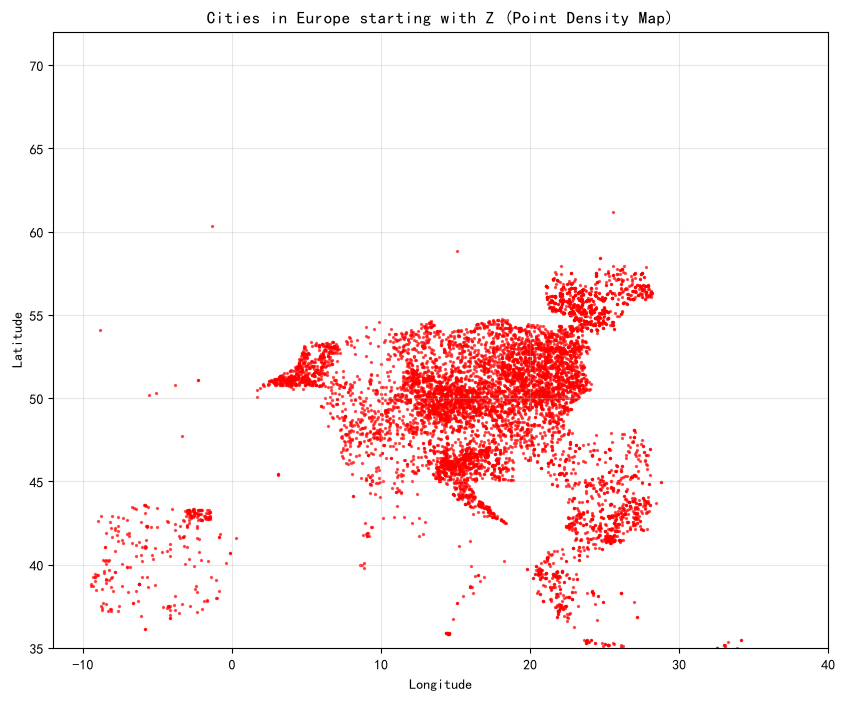

In [30]:
import matplotlib.pyplot as plt

plt.close('all') 
plt.figure(figsize=(10,8))
ax = plt.subplot()

# 绘制散点
scatter = ax.scatter(df_letterZ["lon"], df_letterZ["lat"], c="red", s=2, alpha=0.6)

# 欧洲边界
ax.set_xlim(-12, 40)
ax.set_ylim(35, 72)

ax.set_title(f"Cities in Europe starting with {letter} (Point Density Map)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)

plt.show()

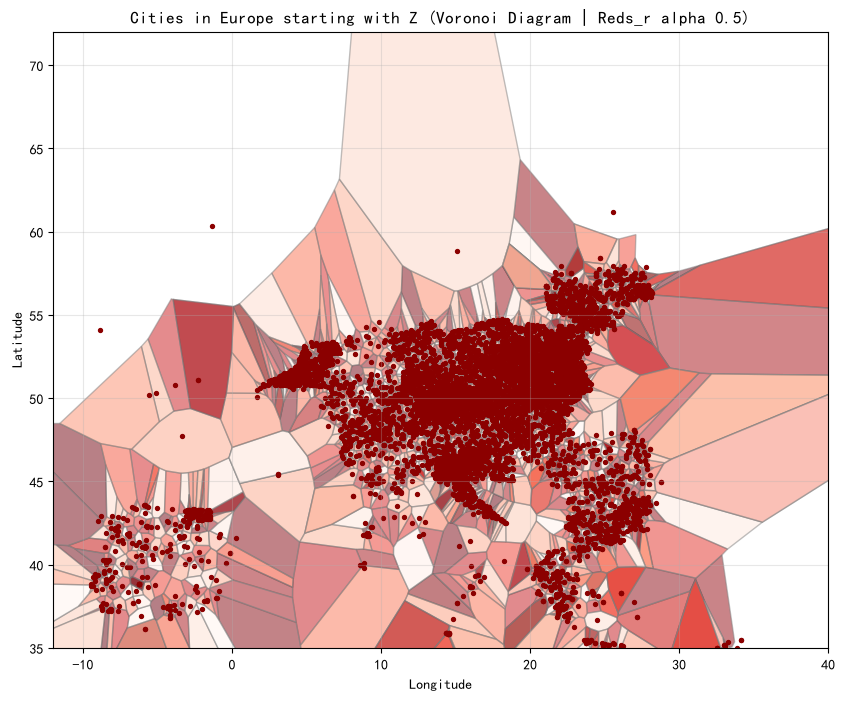

In [33]:
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi
from matplotlib.patches import Polygon
import numpy as np

plt.close('all')
df_plot = df_letterZ.dropna(subset=["lon","lat"])
points = df_plot[["lon", "lat"]].values

# 计算Voronoi
vor = Voronoi(points)
cmap = plt.cm.Reds_r  # 作业指定 Reds_r

fig, ax = plt.subplots(figsize=(10,8))

# 遍历每个区域，只绘制【有限闭合多边形】，去掉无限延伸的尖角
for region_idx in vor.point_region:
    region = vor.regions[region_idx]
    # -1 代表无限顶点，直接跳过，防止超长尖角
    if -1 not in region and len(region) > 0:
        poly_vertices = vor.vertices[region]
        # 颜色映射，这里用随机值演示上色，你也可以换成人口等指标
        fill_color = cmap(np.random.uniform(0,1))
        polygon = Polygon(poly_vertices, facecolor=fill_color, alpha=0.5, edgecolor="gray")
        ax.add_patch(polygon)

# 叠加城市散点
ax.scatter(points[:,0], points[:,1], c="darkred", s=8)

# 锁定欧洲范围，裁剪画面，和示例图保持一致
ax.set_xlim(-12, 40)
ax.set_ylim(35,72)

ax.set_title(f"Cities in Europe starting with {letter} (Voronoi Diagram | Reds_r alpha 0.5)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)
plt.show()

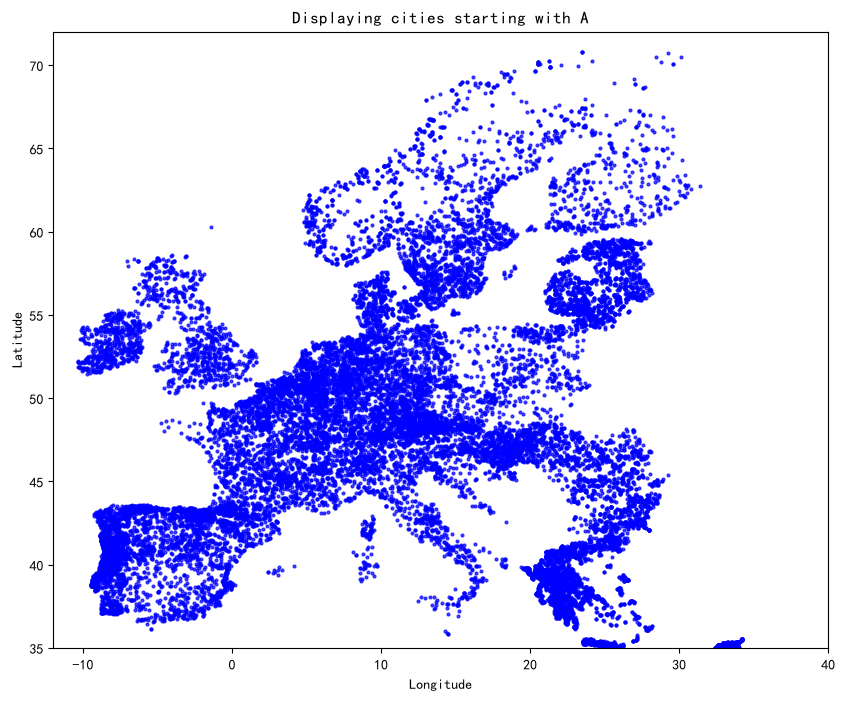

In [35]:
# A-Z字母列表
letters = list(string.ascii_uppercase)
current_idx = 0 # 默认从A开始

# 创建画布
fig, ax = plt.subplots(figsize=(10,8))

# 绘制函数：根据当前字母刷新地图
def draw_map(letter_index):
    ax.clear()
    current_letter = letters[letter_index]
    # 筛选当前首字母城市
    df_sub = df_europe[df_europe['City'].str.upper().str.startswith(current_letter)]
    # 绘制点
    ax.scatter(df_sub["lon"], df_sub["lat"], c="blue", s=4, alpha=0.7)
    ax.set_xlim(-12,40) #欧洲经度范围
    ax.set_ylim(35,72)  #欧洲纬度范围
    ax.set_title(f"Displaying cities starting with {current_letter}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    fig.canvas.draw()

# 键盘按键监听事件（左右箭头）
def on_key(event):
    global current_idx
    if event.key == "right":
        current_idx = (current_idx + 1) % len(letters)
    elif event.key == "left":
        current_idx = (current_idx - 1) % len(letters)
    draw_map(current_idx)

# 绑定键盘事件
fig.canvas.mpl_connect("key_press_event", on_key)

# 初始绘制A开头城市
draw_map(current_idx)
plt.show()